In [1]:
import polars as pl

### POLARS API

In [2]:
df = pl.read_parquet("data/2019-Oct-10M.parquet")
df.collect_schema()

Schema([('event_time', String),
        ('event_type', String),
        ('product_id', Int32),
        ('category_id', Int64),
        ('category_code', String),
        ('brand', String),
        ('price', Float32),
        ('user_id', Int32),
        ('user_session', String)])

In [4]:
df.head()

event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
str,str,i32,i64,str,str,f32,i32,str
"""2019-10-01 00:00:00 UTC""","""view""",44600062,2103807459595387724,null,"""shiseido""",35.790001,541312140,"""72d76fde-8bb3-4e00-8c23-a032df…"
"""2019-10-01 00:00:00 UTC""","""view""",3900821,2053013552326770905,"""appliances.environment.water_h…","""aqua""",33.200001,554748717,"""9333dfbd-b87a-4708-9857-633655…"
"""2019-10-01 00:00:01 UTC""","""view""",17200506,2053013559792632471,"""furniture.living_room.sofa""",null,543.099976,519107250,"""566511c2-e2e3-422b-b695-cf8e6e…"
"""2019-10-01 00:00:01 UTC""","""view""",1307067,2053013558920217191,"""computers.notebook""","""lenovo""",251.740005,550050854,"""7c90fc70-0e80-4590-96f3-13c02c…"
"""2019-10-01 00:00:04 UTC""","""view""",1004237,2053013555631882655,"""electronics.smartphone""","""apple""",1081.97998,535871217,"""c6bd7419-2748-4c56-95b4-8cec9f…"


In [5]:
df.describe()

statistic,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
str,str,str,f64,f64,str,str,f64,f64,str
"""count""","""10000000""","""10000000""",1e7,1e7,"""6775881""","""8612891""",1e7,1e7,"""9999999"""
"""null_count""","""0""","""0""",0.0,0.0,"""3224119""","""1387109""",0.0,0.0,"""1"""
"""mean""",null,null,1.0115e7,2.0567e18,null,null,296.061432,5.3176e8,null
"""std""",null,null,1.1245e7,1.6817e16,null,null,366.910065,1.7159e7,null
"""min""","""2019-10-01 00:00:00 UTC""","""cart""",1.001588e6,2.0530e18,"""accessories.bag""","""a-case""",0.0,1.83503497e8,"""00000083-8816-4d58-a9b8-f52f54…"
"""25%""",null,null,1.005115e6,2.0530e18,null,null,65.25,5.15619279e8,null
"""50%""",null,null,4.900087e6,2.0530e18,null,null,161.910004,5.27467247e8,null
"""75%""",null,null,1.5700074e7,2.0530e18,null,null,361.820007,5.4876831e8,null
"""max""","""2019-10-08 17:26:09 UTC""","""view""",5.560003e7,2.1754e18,"""stationery.cartrige""","""zyxel""",2574.070068,5.58164653e8,"""fffffa1b-a6f0-483a-8f4b-30db24…"


In [6]:
df.get_column("brand").value_counts(sort=True)
# df['brand'].value_counts(sort=True) # Same way to access column, not recommended

brand,count
str,u32
null,1387109
"""samsung""",1235686
"""apple""",1036458
"""xiaomi""",705779
"""huawei""",276702
…,…
"""sabi""",1
"""studio""",1
"""noordi""",1


In [9]:
df.select(
    pl.col("price").median().alias("median_price"),
    pl.col("brand").n_unique().alias("n_unique_brands"),
    pl.col("brand").is_not_null().sum(),
    pl.col("brand").str.len_chars().max().alias("max_brand_length"),
)

median_price,n_unique_brands,brand,max_brand_length
f32,u32,u32,u32
161.910004,2673,8612891,17


In [10]:
df.with_columns(pl.col("price").median().over("brand").alias("median_price_over_brand"))

event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session,median_price_over_brand
str,str,i32,i64,str,str,f32,i32,str,f32
"""2019-10-01 00:00:00 UTC""","""view""",44600062,2103807459595387724,null,"""shiseido""",35.790001,541312140,"""72d76fde-8bb3-4e00-8c23-a032df…",46.02
"""2019-10-01 00:00:00 UTC""","""view""",3900821,2053013552326770905,"""appliances.environment.water_h…","""aqua""",33.200001,554748717,"""9333dfbd-b87a-4708-9857-633655…",33.200001
"""2019-10-01 00:00:01 UTC""","""view""",17200506,2053013559792632471,"""furniture.living_room.sofa""",null,543.099976,519107250,"""566511c2-e2e3-422b-b695-cf8e6e…",107.339996
"""2019-10-01 00:00:01 UTC""","""view""",1307067,2053013558920217191,"""computers.notebook""","""lenovo""",251.740005,550050854,"""7c90fc70-0e80-4590-96f3-13c02c…",411.829987
"""2019-10-01 00:00:04 UTC""","""view""",1004237,2053013555631882655,"""electronics.smartphone""","""apple""",1081.97998,535871217,"""c6bd7419-2748-4c56-95b4-8cec9f…",746.219971
…,…,…,…,…,…,…,…,…,…
"""2019-10-08 17:26:09 UTC""","""view""",22900082,2053013561780732677,"""furniture.bedroom.pillow""","""belashoff""",25.74,518471106,"""708497d0-bed7-476b-af47-66ebda…",25.74
"""2019-10-08 17:26:09 UTC""","""view""",32100001,2060237588744111062,null,null,164.100006,514437524,"""f8fc5c52-ae97-4a64-b6f4-fa3f5f…",107.339996
"""2019-10-08 17:26:09 UTC""","""view""",26400265,2053013563651392361,null,"""lucente""",154.190002,547749418,"""e22d0270-8dea-4cc1-ae99-e78a58…",215.710007


In [11]:
df.with_columns(pl.col("price").median().over("brand").alias("median_price_over_brand")).group_by(
    "event_type", "product_id", "category_id", "category_code", "brand", "price", "median_price_over_brand"
).agg("user_id")

event_type,product_id,category_id,category_code,brand,price,median_price_over_brand,user_id
str,i32,i64,str,str,f32,f32,list[i32]
"""view""",16200012,2053013556344914381,"""kids.fmcg.diapers""","""goo.n""",5.64,17.709999,[517419409]
"""view""",28300027,2053013566243472379,"""accessories.wallet""",null,246.080002,107.339996,"[512539408, 515777440, … 513371539]"
"""purchase""",2501493,2053013564003713919,"""appliances.kitchen.oven""","""smeg""",514.690002,542.070007,[518757041]
"""view""",38600080,2080463777718862211,null,null,10.23,107.339996,[513337948]
"""view""",6000229,2053013560807654091,"""auto.accessories.alarm""","""starline""",138.220001,138.229996,"[527357812, 555854129, … 548517650]"
…,…,…,…,…,…,…,…
"""view""",21404341,2053013561579406073,"""electronics.clocks""",null,20.59,107.339996,"[512421536, 556085057, … 518721292]"
"""view""",12201689,2116907525176557699,"""sport.bicycle""","""axis""",100.389999,95.239998,"[519384146, 519384146, … 552048405]"
"""view""",15200959,2053013553484398879,null,null,53.029999,107.339996,"[514737240, 514737240, … 538590593]"


### Eager vs Lazy Performance

In [12]:
## NOTE: Restart kernel and clean cells at this point to free memory
import polars as pl

In [19]:
df = pl.read_parquet("data/2019-Oct-10M.parquet")  # Eager read

In [20]:
df.with_columns(pl.col("price").median().over("brand").alias("median_price_over_brand")).write_parquet(
    "data/2019-Oct-10M_eager.parquet"
)

In [21]:
del df

In [22]:
df = pl.scan_parquet("data/2019-Oct-10M.parquet")

In [23]:
df.with_columns(pl.col("price").median().over("brand").alias("median_price_over_brand")).sink_parquet(
    "data/2019-Oct-10M_eager.parquet", engine="streaming"
)

In [24]:
df_lazy_brand = pl.scan_parquet("data/2019-Oct-10M.parquet").select("brand").unique()

In [25]:
df_lazy = (
    pl.scan_parquet("data/2019-Oct.parquet")
    .join(df_lazy_brand, on="brand", how="inner")
    .with_columns(pl.col("price").median().over("brand").alias("median_price_over_brand"))
    .group_by("event_type", "product_id", "category_id", "category_code", "brand", "price", "median_price_over_brand")
    .agg(pl.col("user_id"))
    .filter(pl.col("product_id") > 100000)
)

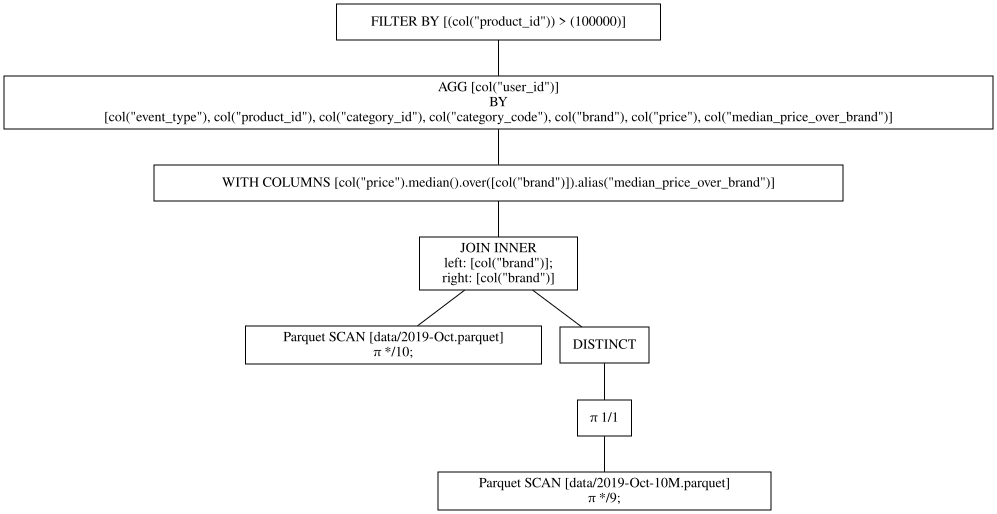

In [16]:
df_lazy.show_graph(optimized=False)

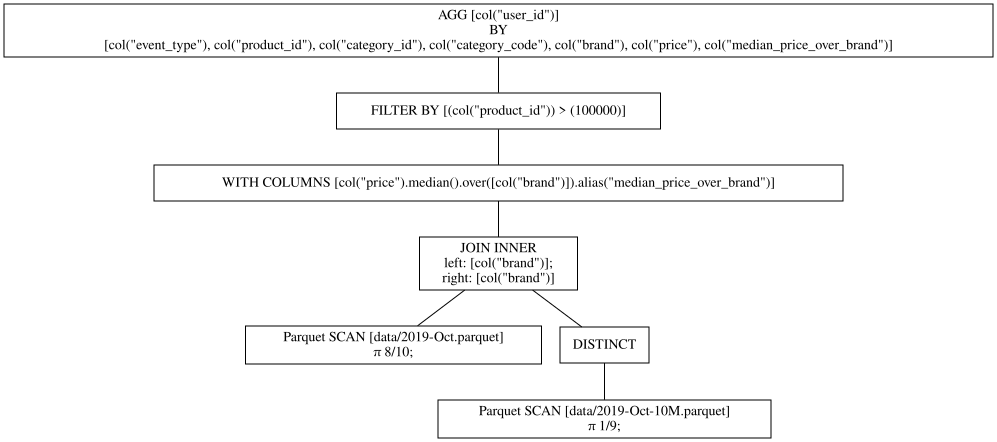

In [17]:
df_lazy.show_graph(optimized=True)

In [28]:
df_lazy.collect(engine="streaming", no_optimization=True).write_parquet("data/2019-Oct-10M_lazy_no_opt.parquet")

In [32]:
df_lazy.collect(engine="streaming").write_parquet("data/2019-Oct-10M_lazy_opt.parquet")

## Arrow interoperability

In [33]:
df = pl.read_parquet("data/2019-Oct-10M.parquet")

In [34]:
df.estimated_size("mb")

1064.689962387085

In [35]:
df_pd = df.to_pandas(use_pyarrow_extension_array=False)
df_pd.head()

,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-01 00:00:00 UTC,view,44600062,2103807459595387724,None,shiseido,35.790001,541312140,72d76fde-8bb3-4e00-8c23-a032dfed738c
1,2019-10-01 00:00:00 UTC,view,3900821,2053013552326770905,appliances.environment.water_heater,aqua,33.200001,554748717,9333dfbd-b87a-4708-9857-6336556b0fcc
2,2019-10-01 00:00:01 UTC,view,17200506,2053013559792632471,furniture.living_room.sofa,None,543.099976,519107250,566511c2-e2e3-422b-b695-cf8e6e792ca8
3,2019-10-01 00:00:01 UTC,view,1307067,2053013558920217191,computers.notebook,lenovo,251.740005,550050854,7c90fc70-0e80-4590-96f3-13c02c18c713
4,2019-10-01 00:00:04 UTC,view,1004237,2053013555631882655,electronics.smartphone,apple,1081.979980,535871217,c6bd7419-2748-4c56-95b4-8cec9ff8b80d


In [36]:
df_pd_arrow = df.to_pandas(use_pyarrow_extension_array=True)
df_pd_arrow.head()

,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-01 00:00:00 UTC,view,44600062,2103807459595387724,<NA>,shiseido,35.790001,541312140,72d76fde-8bb3-4e00-8c23-a032dfed738c
1,2019-10-01 00:00:00 UTC,view,3900821,2053013552326770905,appliances.environment.water_heater,aqua,33.200001,554748717,9333dfbd-b87a-4708-9857-6336556b0fcc
2,2019-10-01 00:00:01 UTC,view,17200506,2053013559792632471,furniture.living_room.sofa,<NA>,543.099976,519107250,566511c2-e2e3-422b-b695-cf8e6e792ca8
3,2019-10-01 00:00:01 UTC,view,1307067,2053013558920217191,computers.notebook,lenovo,251.740005,550050854,7c90fc70-0e80-4590-96f3-13c02c18c713
4,2019-10-01 00:00:04 UTC,view,1004237,2053013555631882655,electronics.smartphone,apple,1081.97998,535871217,c6bd7419-2748-4c56-95b4-8cec9ff8b80d


In [37]:
import duckdb

conn = duckdb.connect("test.duckdb")

In [38]:
conn.sql("CREATE OR REPLACE TABLE pandas_backend as SELECT * from df_pd")

In [42]:
conn.sql("CREATE OR REPLACE  TABLE pandas_arrow as SELECT * from df_pd_arrow")

In [43]:
conn.sql("CREATE OR REPLACE TABLE polars as SELECT * from df")

In [44]:
conn.close()